# IF · K-means · LOF — 개선 결과와 벤치마크 난도 효과

3개 알고리즘의 **전체 / Adapter / 앙상블** 9개 전략이다. 앙상블은 같은 알고리즘의 실제 전체 점수와 Adapter 점수를 합친다.
세 알고리즘의 경보를 단순 OR한 모델이 아니다. 데이터 난도 완화 효과와 모델 자체 효과를 구분해서 읽는다.
이전 결과 노트북은 복구용으로 보존했다. 기존 운영 모델 자동 교체나 GitHub 업로드는 하지 않았다.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p/'code/model_research_v18/report.py').exists())
sys.path.insert(0, str(ROOT/'code'))
from model_research_v18 import report
report.setup(); pd.set_option('display.max_columns', 14); pd.set_option('display.max_rows', 100)
s = report.summary()
selection = report.read(ROOT/'reports/model_research_v18/selection.json')
display(s['protocol'])

{'model_sha256': '5467da57585eb6cb5dec5c65a7d609547afeb992bb72233d54d118e667383993',
 'benchmark_manifest_sha256': '4f5469a098b82372d78499a8e9d9e7541dd58dba61a826626006dc6dc5627e93',
 'no_refit_on_final': True,
 'point_adjustment': False,
 'decision_unit': 'one observed process stream minute',
 'benchmark_modified_in_this_experiment': True,
 'baseline': 'v12 IF/K-means and v14 LOF; parameter changes selected on fresh case-disjoint development only',
 'limitation': 'Adaptive research; not blind external production testing',
 'comparison_stage': 'adjusted',
 'parent_benchmark_sha256': '7f2dc4351af6166416f7694df97fb2050cab8d348e5b29d8451fcc36031f3b36',
 'normal_calibration_and_all_search_cases_disjoint': True}

## 1. 무엇을 몇 개 평가했나?

기본 6개 시나리오 각각 5,000개 이상 사건 사례, 혼합 Hard 1,000개 사례, 총 31,000개와 같은 수의 정상 대조 사례다.
CSV 행, 사례, 1분 판단은 서로 다른 단위다. 정상 배경·빈 시간창도 포함한다.
STATUS=S는 성공 기록이라는 뜻이며 주입된 성능 이상이 없다는 정답이 아니다.

In [2]:
display(pd.DataFrame([{'시나리오': report.TASKS[d['dataset']], '사례 수': d['case_count'],
    '평가 분 수': d['metrics'][0]['n'], '정상 분': d['metrics'][0]['normal'], '이상 분': d['metrics'][0]['anomaly']}
    for d in s['datasets']]))
display(Markdown(f"모든 분을 정상이라 하면 Accuracy는 **{s['pooled'][0]['always_normal_accuracy']*100:.2f}%**다. Accuracy만 높다고 좋은 탐지기가 아니다."))

,시나리오,사례 수,평가 분 수,정상 분,이상 분
0,개별 지연,5000,59984,54891,5093
1,집단 지연,5000,363830,308714,55116
2,컬럼 관계,5000,60000,50000,10000
3,시간대 폭주,5000,398856,357193,41663
4,입력 중단,5000,502488,422499,79989
5,점진적 악화,5000,602814,452824,149990
6,혼합 Hard,1000,179794,139797,39997


모든 분을 정상이라 하면 Accuracy는 **82.39%**다. Accuracy만 높다고 좋은 탐지기가 아니다.

## 2. 모델만 바꿨을 때와 데이터도 완화했을 때

`기존`은 직전에 보고한 v14의 9개 결과다. `모델만 변경`은 **같은 기존 mild-v1 데이터**에서 새 모델을 평가했다.
`난도 조정 후`는 같은 새 모델을 mild-v2에 넣은 결과다. 두 상승분을 모두 모델 개선이라고 부르지 않는다.
탐색에 쓰인 보수적 기준(v12 IF/K-means, v14 LOF)과 이전에 보고한 v14 IF 연구 후보도 구분한다.

In [3]:
display(report.effects().iloc[:, :6])
display(report.metric_changes())
display(report.table(report.stage_summary('parent')['pooled']))

,모델,기존 F1 (%),모델만 변경 F1 (%),모델 개선 F1 (%p),난도 조정 후 F1 (%),난도 효과 F1 (%p)
0,IF 전체,41.05,42.74,1.69,45.39,2.65
1,IF Adapter,27.24,28.59,1.34,30.99,2.40
2,IF 앙상블,36.29,45.32,9.02,47.78,2.47
3,K-means 전체,40.44,41.29,0.85,44.20,2.91
4,K-means Adapter,36.81,38.17,1.37,40.84,2.67
5,K-means 앙상블,41.96,42.36,0.40,45.19,2.83
6,LOF 전체,29.43,40.58,11.15,43.44,2.85
7,LOF Adapter,30.84,34.43,3.59,37.53,3.10
8,LOF 앙상블,31.56,41.10,9.54,43.86,2.76


,모델,Accuracy 변화 (%p),Precision 변화 (%p),Recall 변화 (%p),F1 변화 (%p),정상 오탐 변화 (%p)
0,IF 전체,1.04,9.12,-0.06,1.69,-1.26
1,IF Adapter,-0.05,-2.85,1.22,1.34,0.31
2,IF 앙상블,1.36,5.76,8.16,9.02,0.05
3,K-means 전체,-0.01,-0.72,1.07,0.85,0.23
4,K-means Adapter,-0.62,-4.37,2.74,1.37,1.31
5,K-means 앙상블,0.23,1.55,0.04,0.40,-0.28
6,LOF 전체,0.56,-0.53,11.32,11.15,1.66
7,LOF Adapter,0.07,-0.94,3.61,3.59,0.67
8,LOF 앙상블,0.37,-0.57,10.40,9.54,1.71


,모델,평가 분 수,Accuracy (%),Precision (%),Recall (%),F1 (%),정상 오탐 (%)
0,IF 전체,2167766,86.05,72.25,30.35,42.74,2.41
1,IF Adapter,2167766,84.55,68.90,18.03,28.59,1.69
2,IF 앙상블,2167766,86.20,70.76,33.33,45.32,2.85
3,K-means 전체,2167766,85.12,63.89,30.50,41.29,3.57
4,K-means Adapter,2167766,83.41,52.92,29.85,38.17,5.50
5,K-means 앙상블,2167766,84.92,61.50,32.31,42.36,4.19
6,LOF 전체,2167766,84.52,59.40,30.82,40.58,4.36
7,LOF Adapter,2167766,83.97,57.66,24.54,34.43,3.73
8,LOF 앙상블,2167766,84.20,56.96,32.14,41.10,5.03


## 3. 최종 현재 데이터에서의 9개 성능

Precision은 경보 중 실제 이상 비율, Recall은 이상 분을 잡은 비율, F1은 둘의 조화 평균이다.
정상 오탐률도 함께 본다. 정상·이상 비율과 사건 길이가 바뀌면 Accuracy·F1도 달라진다.
그래프는 일반 막대이며, 각 알고리즘의 전체·Adapter·앙상블을 나란히 비교한다.

,모델,평가 분 수,Accuracy (%),Precision (%),Recall (%),F1 (%),정상 오탐 (%)
0,IF 전체,2167766,86.13,74.05,32.73,45.39,2.45
1,IF Adapter,2167766,84.46,71.16,19.81,30.99,1.72
2,IF 앙상블,2167766,86.28,72.45,35.65,47.78,2.90
3,K-means 전체,2167766,85.17,65.52,33.35,44.20,3.75
4,K-means Adapter,2167766,83.42,54.95,32.50,40.84,5.70
5,K-means 앙상블,2167766,84.97,63.16,35.18,45.19,4.39
6,LOF 전체,2167766,84.58,61.39,33.61,43.44,4.52
7,LOF Adapter,2167766,84.00,60.06,27.29,37.53,3.88
8,LOF 앙상블,2167766,84.25,58.96,34.92,43.86,5.20


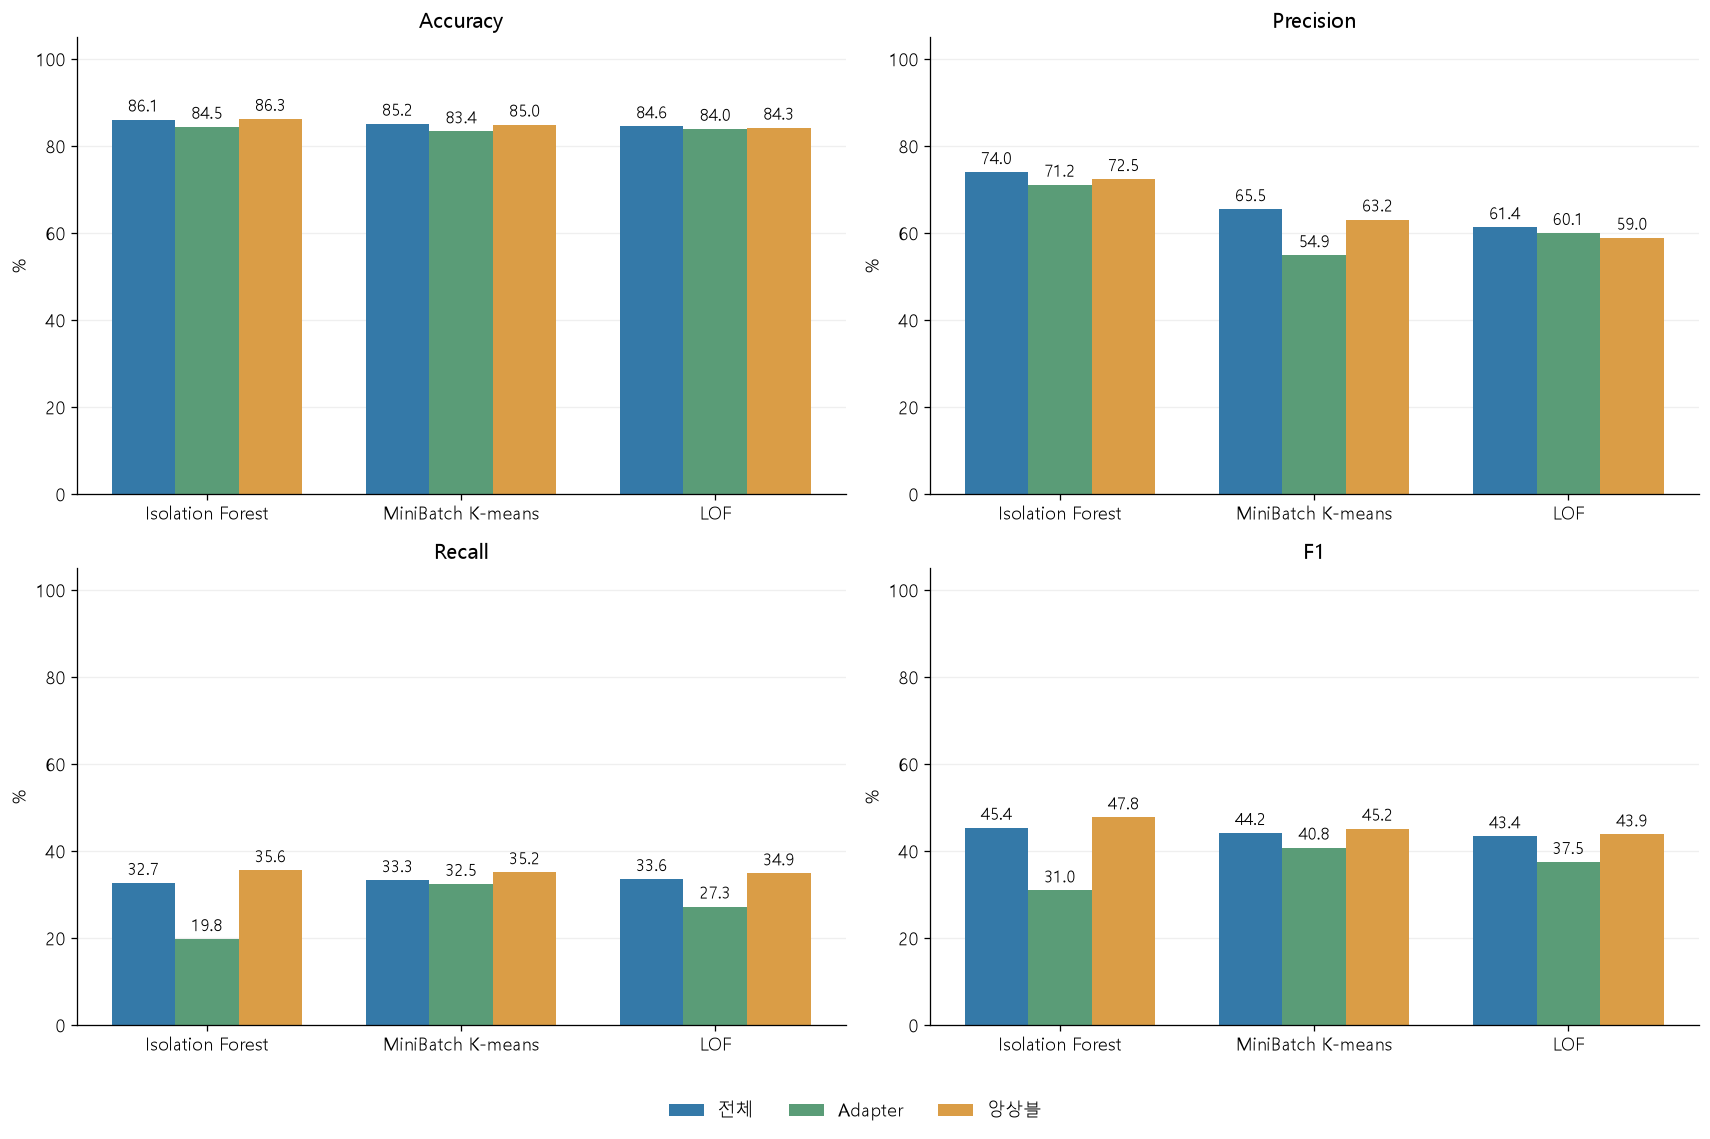

In [4]:
display(report.table(s['pooled']))
report.bars(); plt.show()

## 4. 시나리오별 장단점

왼쪽 F1과 오른쪽 정상 오탐을 같이 읽는다. 긴 점진적 악화가 합산 지표를 크게 좌우하므로,
6개 기본 시나리오를 같은 비중으로 평균한 macro도 따로 본다. Hard는 완화하지 않았다.
어떤 시나리오에서 좋아졌다고 모든 장애와 실제 운영 기간에서 좋아졌다고 일반화하지 않는다.

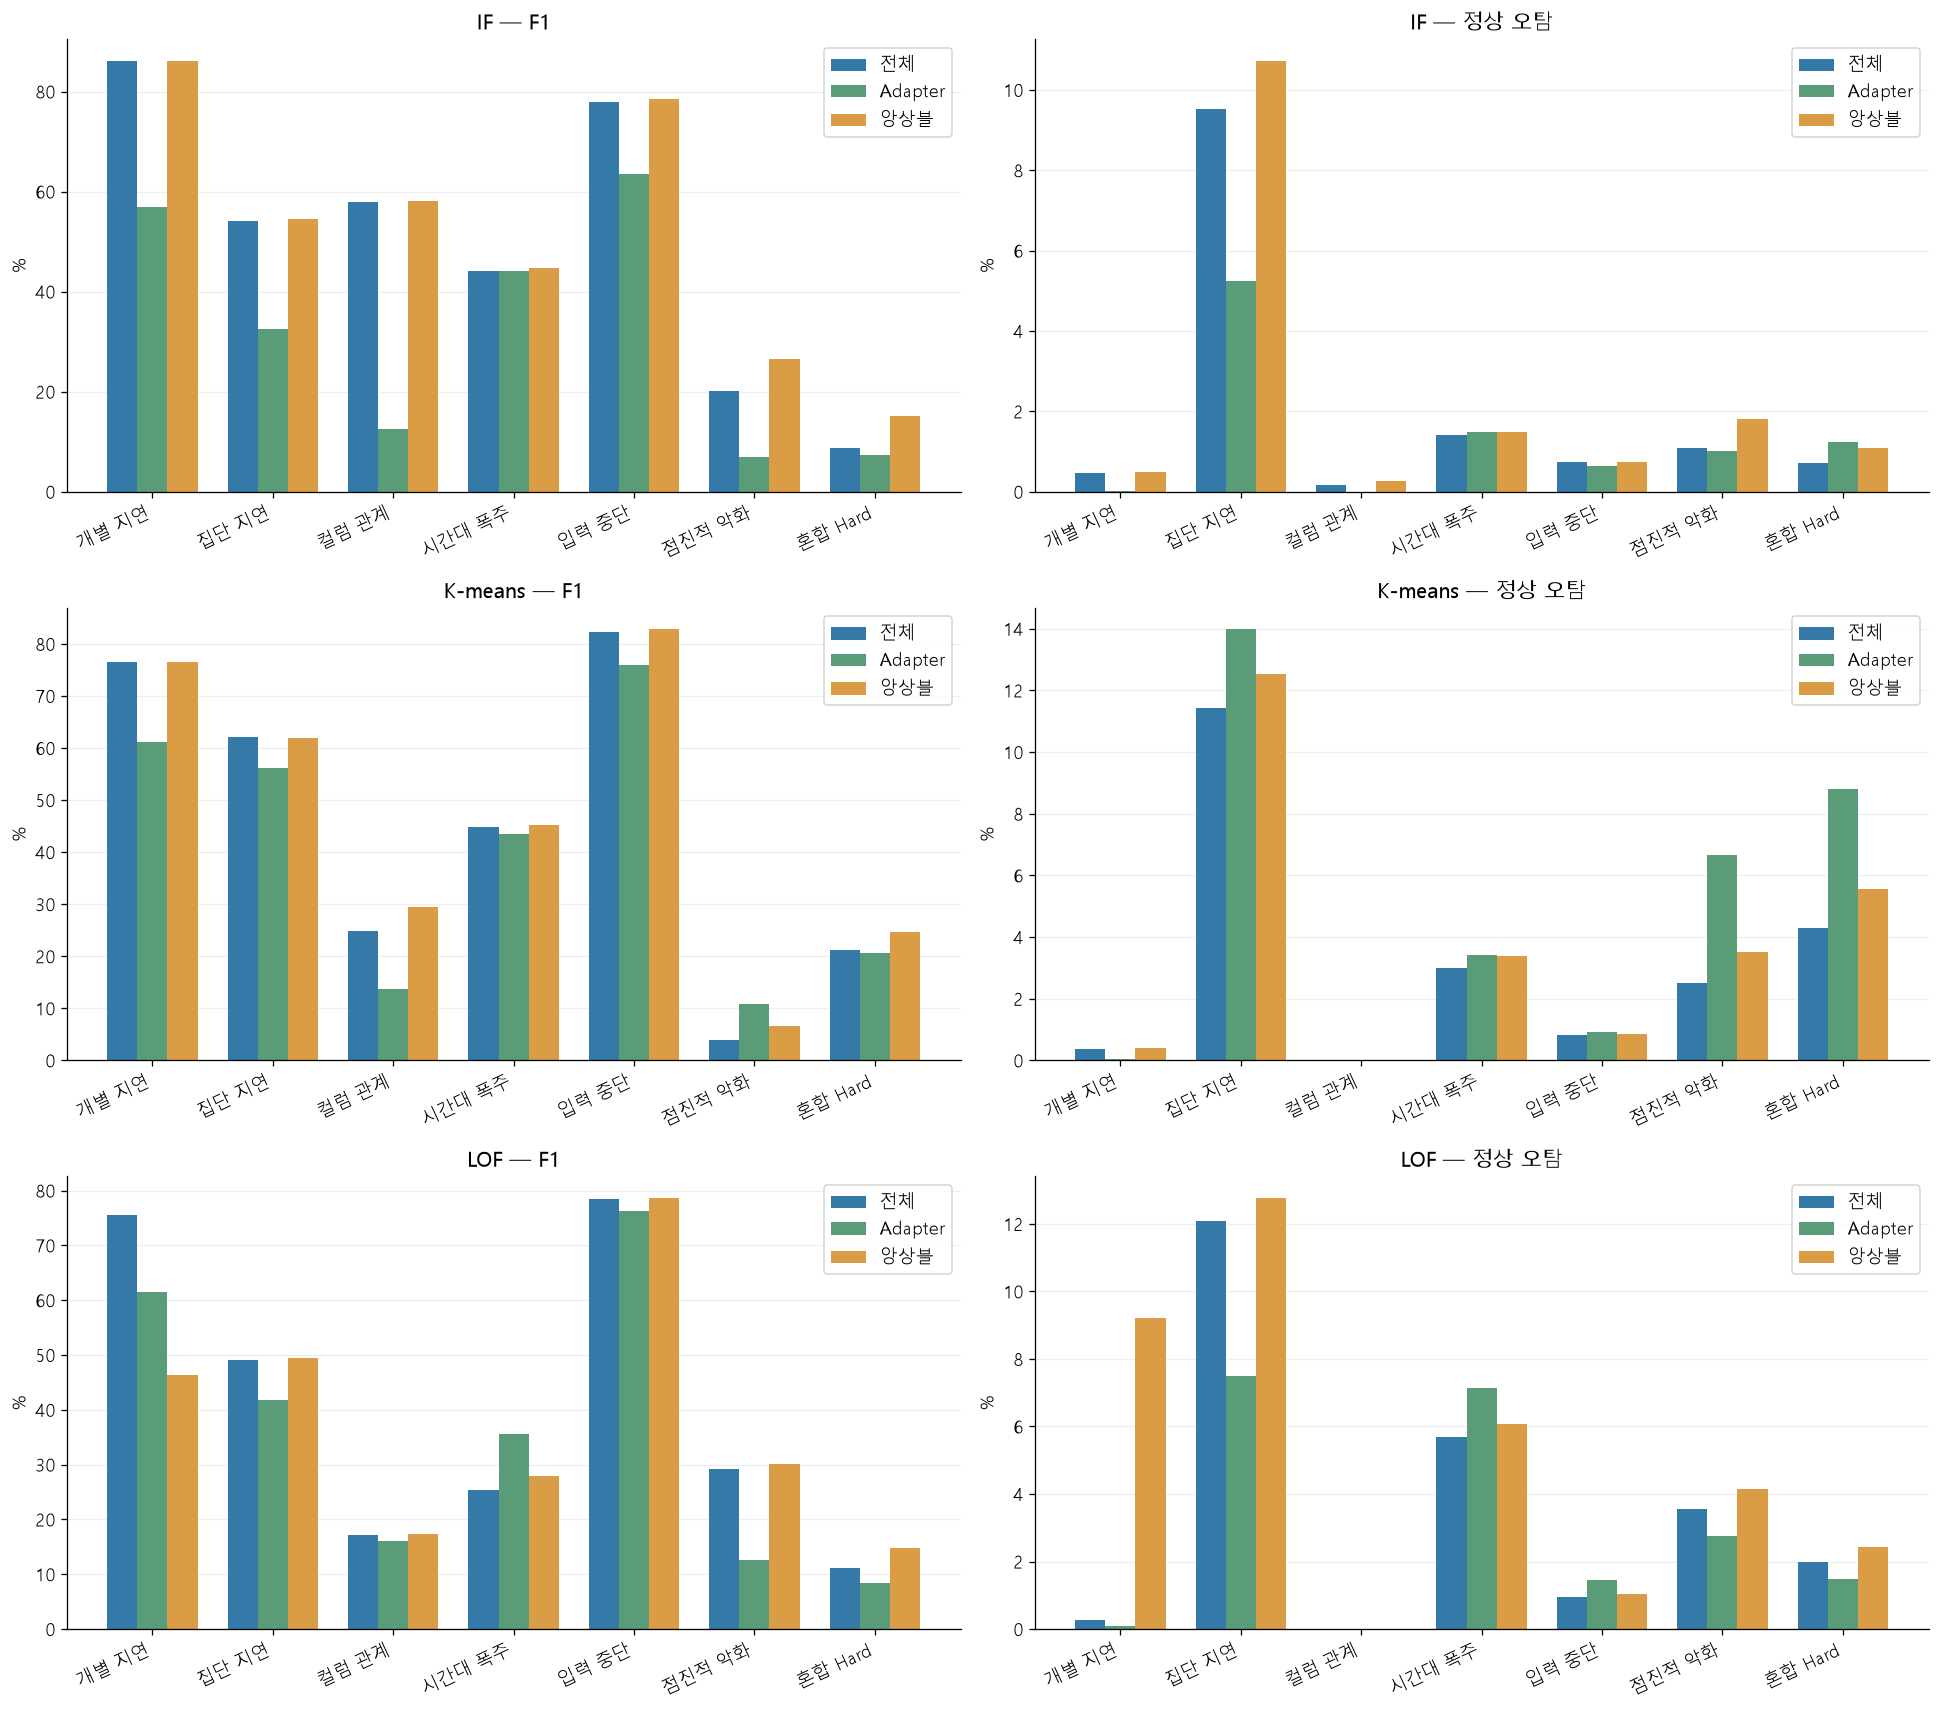

,시나리오,모델,precision,recall,f1,normal_false_positive_rate
0,개별 지연,IF 전체,94.14,79.46,86.18,0.46
1,개별 지연,IF Adapter,99.66,39.78,56.86,0.01
2,개별 지연,IF 앙상블,93.66,79.54,86.03,0.50
3,개별 지연,K-means 전체,94.21,64.52,76.59,0.37
4,개별 지연,K-means Adapter,98.69,44.35,61.20,0.05
5,개별 지연,K-means 앙상블,93.84,64.66,76.56,0.39
6,개별 지연,LOF 전체,95.72,62.28,75.46,0.26
7,개별 지연,LOF Adapter,97.86,44.92,61.58,0.09
8,개별 지연,LOF 앙상블,37.67,59.95,46.27,9.20
9,집단 지연,IF 전체,51.58,56.80,54.06,9.52


,모델,평가 분 수,Accuracy (%),Precision (%),Recall (%),F1 (%),정상 오탐 (%)
0,IF 전체,None,89.34,81.40,47.84,56.73,2.23
1,IF Adapter,None,86.93,77.58,25.93,36.13,1.40
2,IF 앙상블,None,89.37,80.24,49.49,58.09,2.59
3,K-means 전체,None,88.01,70.48,43.95,49.07,3.02
4,K-means Adapter,None,86.49,69.90,38.06,43.56,4.17
5,K-means 앙상블,None,87.94,70.50,45.62,50.44,3.45
6,LOF 전체,None,87.04,71.32,39.10,45.78,3.76
7,LOF Adapter,None,86.55,69.61,33.30,40.66,3.15
8,LOF 앙상블,None,85.56,61.30,39.79,41.62,5.54


,모델,기존 macro-F1 (%),모델만 변경 macro-F1 (%),모델 변화 (%p)
0,IF 전체,55.48,54.80,-0.68
1,IF Adapter,34.12,34.33,0.21
2,IF 앙상블,42.47,56.23,13.76
3,K-means 전체,46.50,46.32,-0.19
4,K-means Adapter,41.26,41.33,0.07
5,K-means 앙상블,47.49,47.59,0.10
6,LOF 전체,27.77,43.57,15.80
7,LOF Adapter,32.63,38.77,6.15
8,LOF 앙상블,31.46,39.55,8.09


종합 F1이 상승해도 같은 비중의 시나리오 평균이나 특정 시나리오 성능은 떨어질 수 있다. 따라서 종합 순위만으로 모든 업무에 적용할 모델을 확정하지 않는다.

In [5]:
report.scenario_bars(); plt.show()
display(report.task_metrics())
display(report.table(s['basic_macro']))
display(report.macro_effects())
display(Markdown('종합 F1이 상승해도 같은 비중의 시나리오 평균이나 특정 시나리오 성능은 떨어질 수 있다. 따라서 종합 순위만으로 모든 업무에 적용할 모델을 확정하지 않는다.'))

## 5. 실제 모델 구조와 성격

| 모델 | 점수의 근거 | 이번 변경과 한계 |
|---|---|---|
| IF | 정상에서 쉽게 분리되는 희귀 조합 | 기존 분기 유지 + 정상 학습 IF 시간 변화 분기. 거리만 보는 모델이 아님 |
| K-means | 정상 군집 중심에서의 거리 | 재학습/시간 분기 후보가 기존 군집을 넘지 못해 군집 보존, 정상 보정·결합 개선 |
| LOF | 가까운 정상 이웃과의 밀도 차이 | novelty=True, 기존 조건부/트래픽 채널 + 정상 학습 시간 변화 분기. 이웃 중복·정상 다양성에 민감 |

전체는 v15의 검증된 Recall 중심 후보, Adapter는 v17의 보수적 보정 후보다.
각 알고리즘의 실제 두 출력에 정상 참고 집단에서 구한 스케일을 적용하고 mean/max·가중치·threshold를 탐색했다.
지원되지 않는 Adapter는 전체와 정확히 동일한 점수/판정으로 fallback한다.

In [6]:
display(pd.DataFrame([{'알고리즘': a, '전체 가중치': r['global_weight'], '결합': r['combination'],
    '정상 분위수': r['quantile'], '보정 alpha': r['alpha'], '탐색 경보 제약 충족': r['ensemble_relative_constraints_met']}
    for a,r in selection['families'].items()]))
manifest = report.read(ROOT/'reports/model_research_v18/handoff/manifest.json')
display(pd.DataFrame([{'알고리즘': m['algorithm'], '지원 Adapter': ', '.join(m['expert_adapters']),
    '모델 크기 (MiB)': m['bytes']/1024**2} for m in manifest['models']]).round(2))

,알고리즘,전체 가중치,결합,정상 분위수,보정 alpha,탐색 경보 제약 충족
0,if,0.9,mean,0.950,0.5,True
1,kmeans,0.9,mean,0.950,0.5,True
2,lof,0.9,mean,0.975,0.5,True


,알고리즘,지원 Adapter,모델 크기 (MiB)
0,if,"DB.READER, DB.WRITER, FILE.READER, FILE.WRITER...",33.12
1,kmeans,"DB.READER, DB.WRITER, FILE.READER, FILE.WRITER...",1.11
2,lof,"DB.READER, DB.WRITER, FILE.READER, FILE.WRITER...",8.82


## 6. 어떤 피처·설정을 개선했나?

- 완료 로그가 없는 분을 새 시간 피처에서 지연 0으로 채우지 않고 건너뛴다. 보존한 legacy 피처의 과거 처리는 별개다.
- 이미 관측된 초반 최대 8개 완료 분의 median/MAD 대비 소요시간 변화, 최근 15분 변화·추세, 양의 변화 비율, EWMA.
  초반이 정상이라고 가정하지 않는다. 초반부터 이상이면 이 피처가 놓칠 수 있어 원래 조건부 분기를 남긴다.
- IF 시간 분기 후보 max_samples 512/2,048, trees 256/384. LOF 후보 k=30/75, reference 최대 2,048.
- 군집 K와 OAS whitening, 입력 미세 수치 안정화, 처리량 조건부 잔차 시간 분기도 시험했지만 무조건 채택하지 않았다.
- 정상 보정은 독립 사례 수로 수축한다: `선택 alpha × min(사례 수 / 30, 1)`.
  30은 이 연구의 휴리스틱이며 통계적 오탐 보장이나 새 하드 룰이 아니다.

새 모델이 항상 모든 지표를 올리는 것은 아니다. 아래 실제 before/after와 탈락 실험을 근거로 판단한다.

## 7. 입력 분포 — 설명용 표본

청크마다 고정 seed로 최대 120분을 뽑았다. 정상/이상 집단별 합은 100%이며 전체 빈도 비율 추정치가 아니다.
실행 수는 log(1+x), 시간은 log(1+ms)다. 양끝 0.5%는 끝 막대에 합쳤지만 성능 집계에서는 자르지 않았다.
소요시간은 완료 관측이 있는 분, 새 변화·추세는 과거 완료 관측이 충분한 분만 그린다. 미관측을 계산상 채운 0은 분포에 넣지 않는다.
반대로 실행 수의 실제 0은 입력 중단을 설명하는 값이므로 포함한다. 제목 아래의 n은 그림에서 사용한 표본 수다.
새 초반 대비/추세 피처는 IF·LOF 전체 모델에 쓰이며 K-means가 새 시간 분기를 채택했다는 뜻은 아니다.

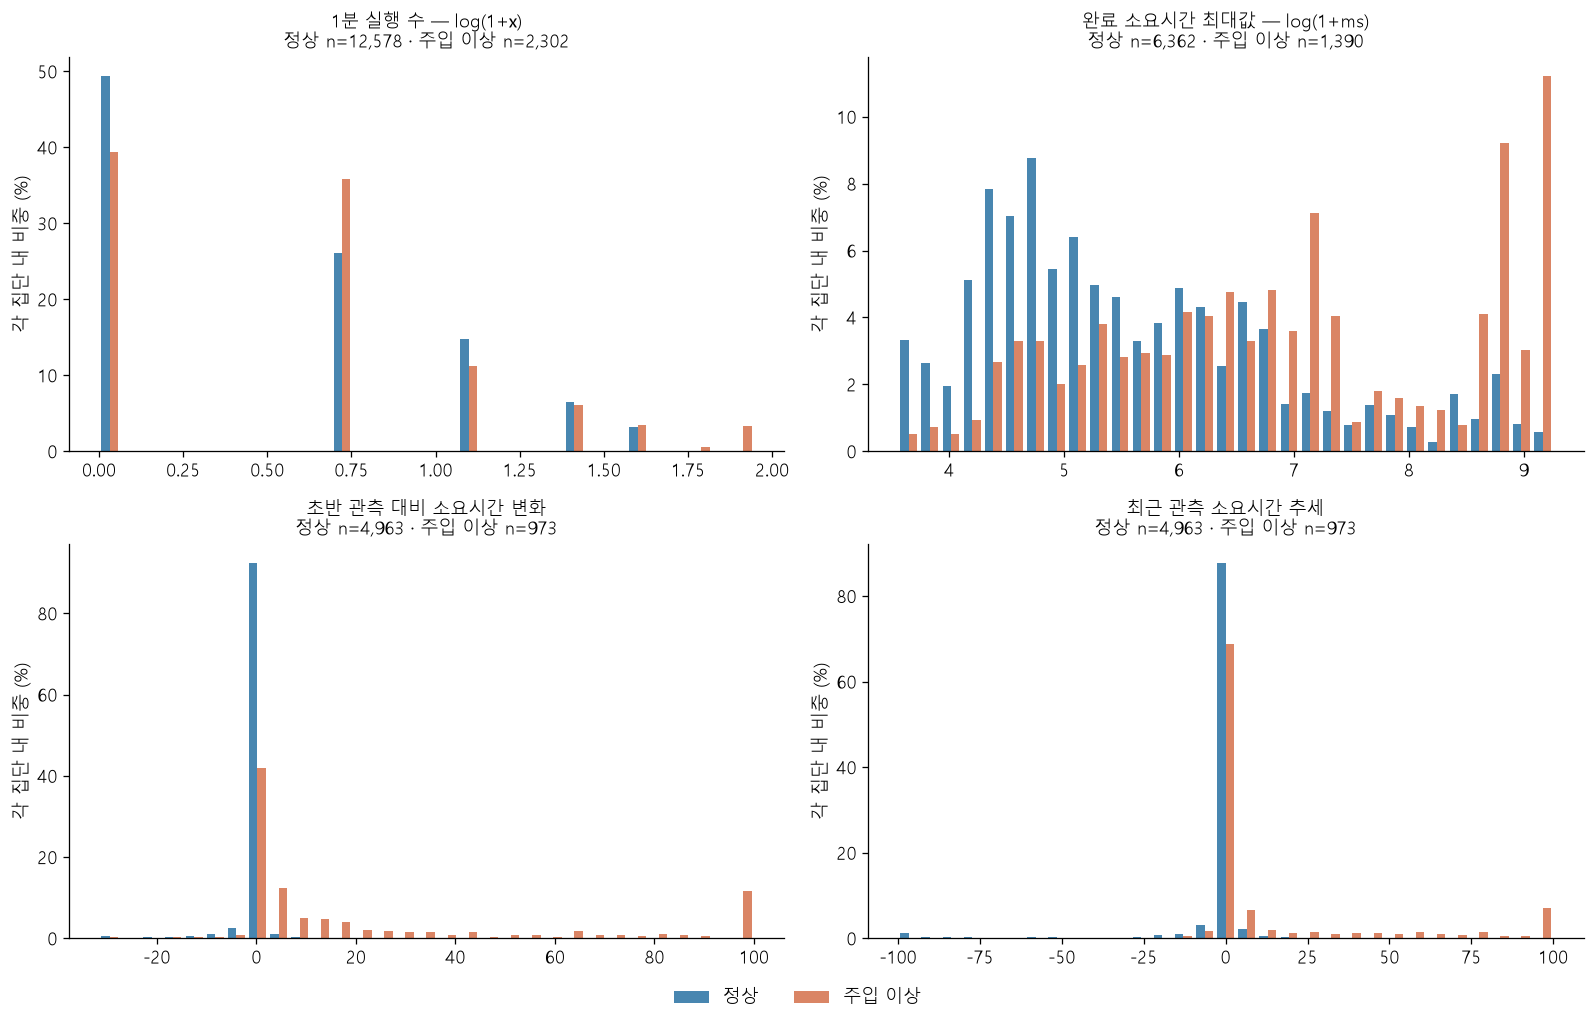

In [7]:
report.input_histograms(); plt.show()

## 8. 점수 분포와 threshold 선

0보다 큰 **점수 - 해당 문맥의 threshold**이면 이상이다. 정상의 오른쪽은 오탐, 이상의 왼쪽은 미탐이다.
알고리즘별 단위가 달라 패널 간 절대 너비를 비교하지 않는다. 0 동률은 정상 판정이므로 왼쪽 구간에 넣었다.
파일별 최대 5,000분 표본, 집단별 100%, 양끝 0.5% 끝 bin 처리다. 일반 나란한 막대 히스토그램이다.

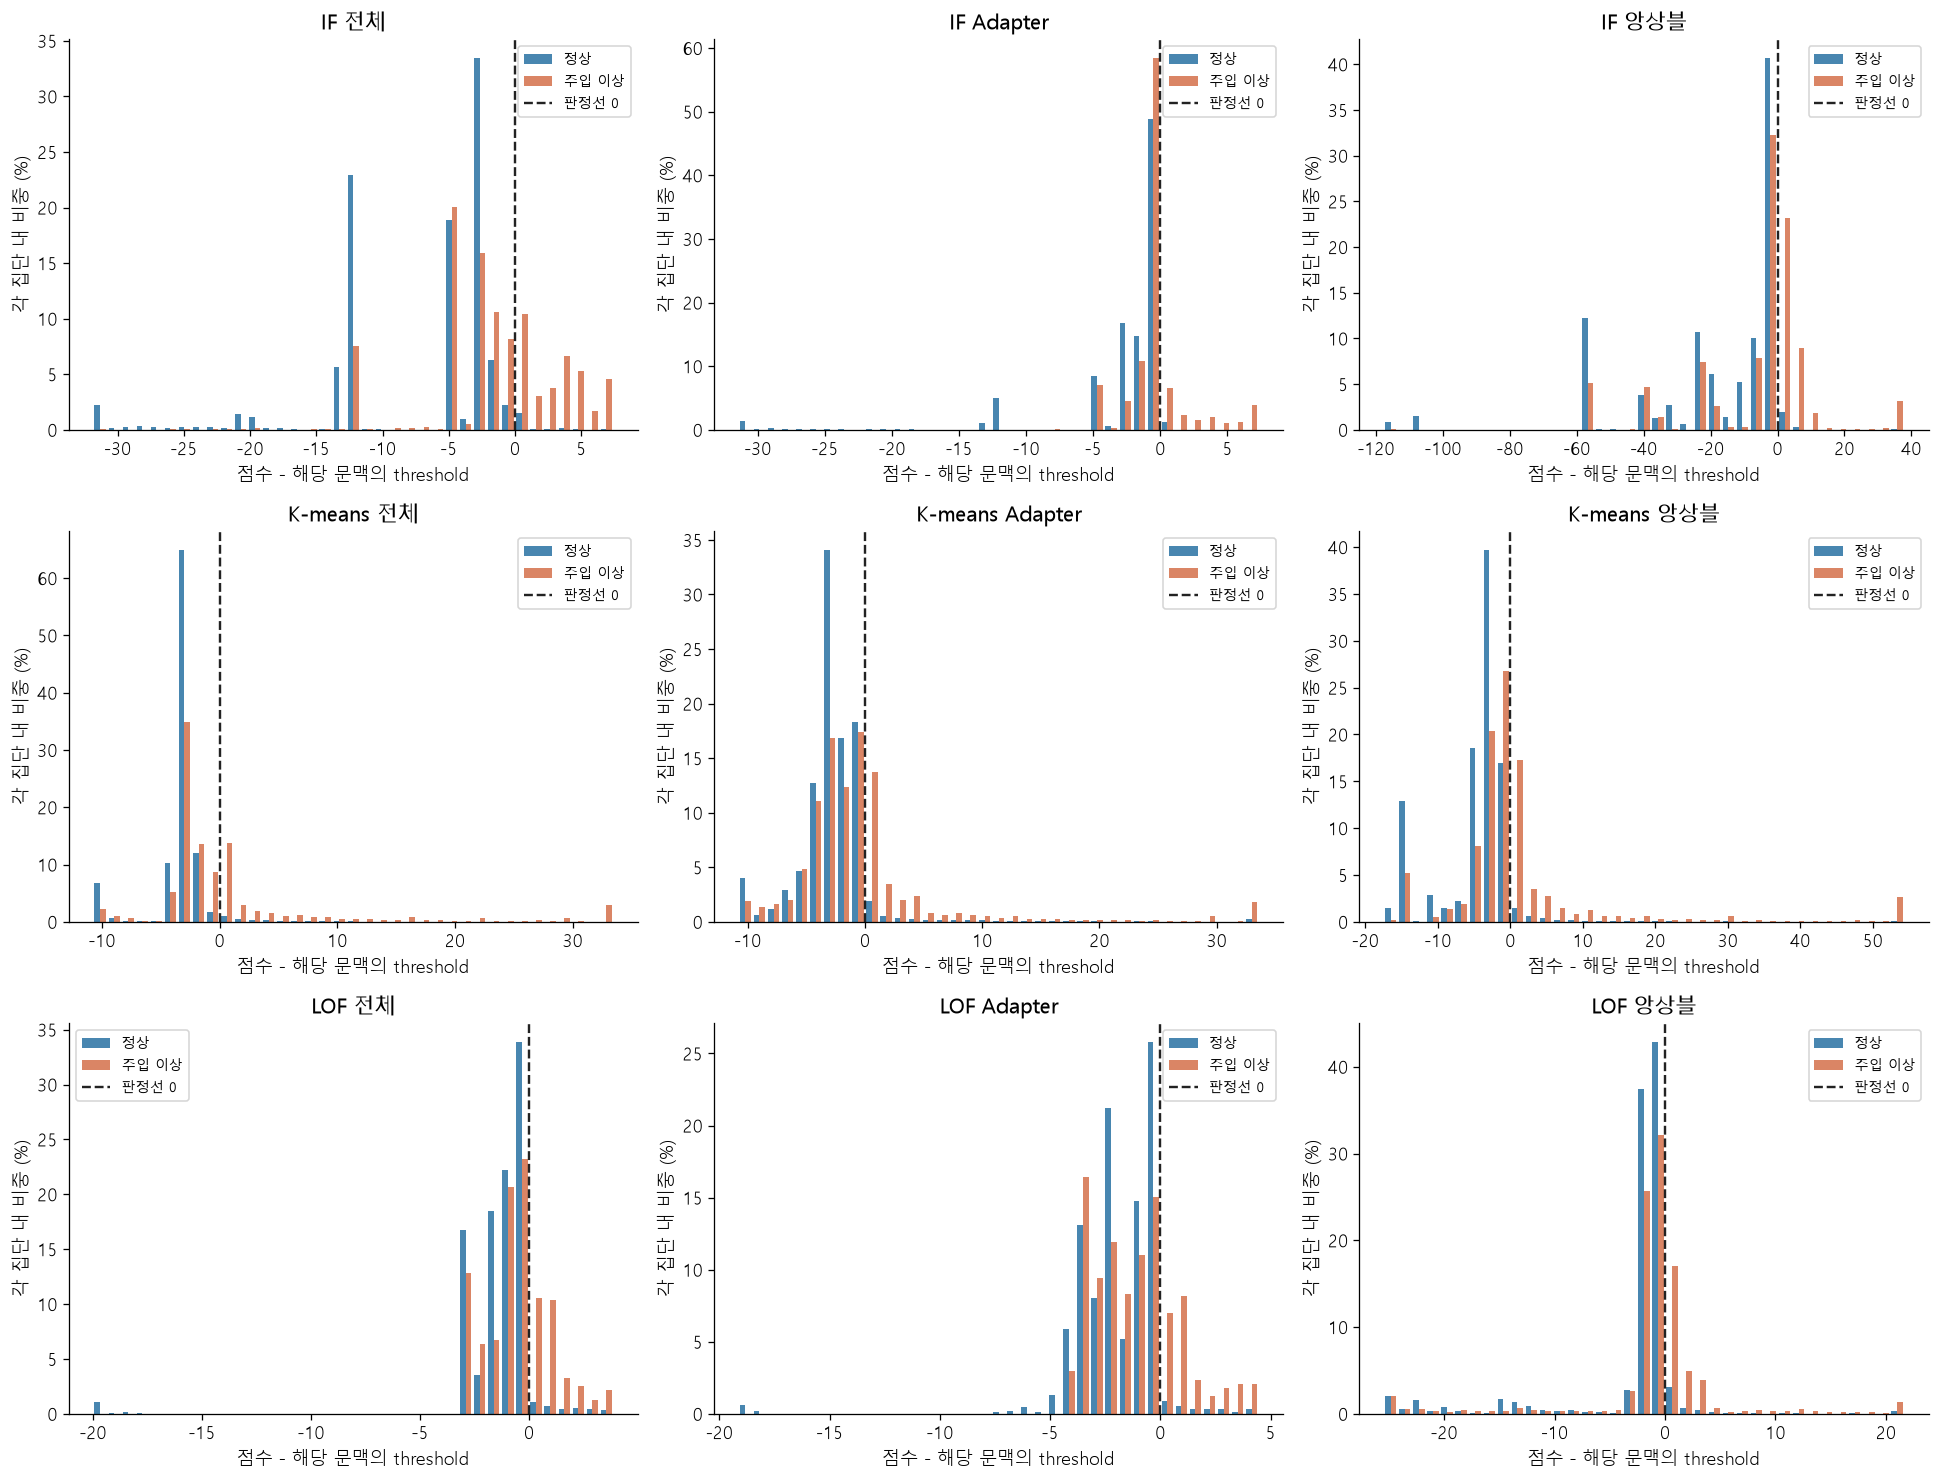

,알고리즘,Adapter,단계,관측 gate,정상 분위수,결합 점수 경계,전체 가중치,독립 정상 사례 수
0,if,DB.READER,startup,0,0.950,-55.05131,0.9,61
1,if,DB.READER,startup,1,0.950,-0.34003,0.9,19
2,if,DB.READER,startup,2,0.950,-0.39583,0.9,98
3,if,DB.READER,startup,3,0.950,-0.16477,0.9,50
4,if,DB.READER,steady,0,0.950,-58.80647,0.9,32
5,if,DB.READER,steady,1,0.950,-21.50234,0.9,68
6,if,DB.READER,steady,2,0.950,-0.16107,0.9,9
7,if,DB.READER,steady,3,0.950,-0.62112,0.9,68
40,kmeans,DB.READER,startup,0,0.950,-15.09116,0.9,61
41,kmeans,DB.READER,startup,1,0.950,-0.56971,0.9,19


,알고리즘,경로,Adapter 문맥,단계,관측 gate,정상 분위수,기존 margin의 보정 경계,보정 정상 분,보정 alpha
0,if,전체,GLOBAL,startup,0,0.999,-12.23362,1005,0.5
1,if,전체,GLOBAL,startup,1,0.999,-0.68068,130,0.5
2,if,전체,GLOBAL,startup,2,0.999,6.63211,1220,0.5
3,if,전체,GLOBAL,startup,3,0.999,0.99024,344,0.5
8,if,Adapter,DB.READER,startup,0,0.990,-1.90293,176,1.0
9,if,Adapter,DB.READER,startup,1,0.990,0.00000,130,1.0
10,if,Adapter,DB.READER,startup,2,0.990,-1.90293,225,1.0
11,if,Adapter,DB.READER,startup,3,0.990,0.00000,344,1.0
48,kmeans,전체,GLOBAL,startup,0,0.995,-3.35359,1005,0.5
49,kmeans,전체,GLOBAL,startup,1,0.995,-0.70482,130,0.5


단계 startup/steady는 스트림 초기/이후 문맥이며 정답 구분이 아니다. 관측 gate는 0=둘 다 미평가, 1=트래픽만, 2=지연만, 3=둘 다 평가, -1=gate를 구분하지 않는 보정이다. 정상 분위수에 alpha·사례 수 보정이 적용되므로 99% 분위수가 실제 오탐 1%를 보장하지 않는다. 앙상블 경계와 실제 사용하는 전체·지원 Adapter 경계는 handoff manifest 및 동결 모델에 기록된다.

In [8]:
report.score_histograms(); plt.show()
thresholds = report.thresholds()
display(thresholds.groupby('알고리즘', sort=False).head(8))
display(report.source_thresholds().groupby(['알고리즘','경로'], sort=False).head(4))
display(Markdown('단계 startup/steady는 스트림 초기/이후 문맥이며 정답 구분이 아니다. 관측 gate는 0=둘 다 미평가, 1=트래픽만, 2=지연만, 3=둘 다 평가, -1=gate를 구분하지 않는 보정이다. 정상 분위수에 alpha·사례 수 보정이 적용되므로 99% 분위수가 실제 오탐 1%를 보장하지 않는다. 앙상블 경계와 실제 사용하는 전체·지원 Adapter 경계는 handoff manifest 및 동결 모델에 기록된다.'))

## 9. 탐지·오탐·미탐 사례와 실제 근거

실제 판정 근거는 저장된 margin > 0 여부다. 실행 수·무실행 연속 길이·지연 피처는 설명 단서이며 인과적 원인이나 SHAP 기여도가 아니다.
각 종류에서 처음 발견된 사례를 보여준다. 대표 통계로 해석하지 않는다.

In [9]:
examples = pd.DataFrame(report.read(report.location()/'decision_examples.json'))
display(examples.groupby(['method','outcome'], sort=False).head(1)[['method','outcome','dataset','adapterType',
    'score_minus_threshold','native_execution_arrivals','zero_run','duration_p95_ms','expert_available']])

,method,outcome,dataset,adapterType,score_minus_threshold,native_execution_arrivals,zero_run,duration_p95_ms,expert_available
0,if_global,TP,individual_delay,FILE.READER,3.548540,1.0,0.000000,22103.000000,True
4,if_global,FP,individual_delay,FILE.READER,3.548540,1.0,0.000000,2855.999947,True
8,if_global,FN,individual_delay,FILE.WRITER,-25.975700,1.0,0.000000,811.000000,True
12,if_adapter,TP,individual_delay,DB.UPDATER,6.632107,1.0,0.000000,6305.000000,False
16,if_adapter,FP,individual_delay,DB.WRITER,0.202579,1.0,0.000000,2011.000156,True
20,if_adapter,FN,individual_delay,FILE.WRITER,-1.323375,1.0,0.000000,811.000000,True
24,if_ensemble,TP,individual_delay,FILE.READER,4.558342,1.0,0.000000,22103.000000,True
28,if_ensemble,FP,individual_delay,FILE.READER,4.558342,1.0,0.000000,2855.999947,True
32,if_ensemble,FN,individual_delay,FILE.WRITER,-41.868427,1.0,0.000000,811.000000,True
36,kmeans_global,TP,individual_delay,FILE.READER,38.025691,1.0,0.000000,22103.000000,True


## 10. 사례 단위 분할과 새 확인 사례

보정 정상 90개/시나리오를 가져오면 그 paired 이상 사례도 탐색에서 함께 제외했다.
탐색 90개/시나리오, 초기 확인 180개/시나리오. 초기 확인은 구조 문제를 진단하는 데 썼으므로 독립 최종 평가라고 재사용하지 않는다.
최종 후보 동결 후 새 seed의 240개/시나리오를 추가 확인했다. 확인 결과로 다시 선택하지 않았다.
원본 pool/생성기를 공유하고 기존 벤치마크를 이미 살펴본 연구이므로 외부 블라인드 운영 성능은 아니다.

In [10]:
validation = report.read(ROOT/'reports/model_research_v18/validation_results.json')
display({k:v for k,v in validation.items() if k != 'results'})
for i,a in enumerate(('if','kmeans','lof')):
    display(report.table(validation['results'][a]['baseline']['pooled'], offset=i*3).assign(집단='기준'))
    display(report.table(validation['results'][a]['candidate']['pooled'], offset=i*3).assign(집단='최종 후보'))

{'seed': 19270042,
 'cases_per_scenario': 240,
 'case_ids_disjoint_all_development_and_prior_confirmation': True,
 'models_reselected': False}

,모델,평가 분 수,Accuracy (%),Precision (%),Recall (%),F1 (%),정상 오탐 (%),집단
0,IF 전체,95470,85.91,70.04,21.70,33.13,1.78,기준
1,IF Adapter,95470,85.58,76.77,14.84,24.88,0.86,기준
2,IF 앙상블,95470,86.44,75.62,23.20,35.50,1.43,기준


,모델,평가 분 수,Accuracy (%),Precision (%),Recall (%),F1 (%),정상 오탐 (%),집단
0,IF 전체,95470,87.09,72.01,32.36,44.66,2.41,최종 후보
1,IF Adapter,95470,85.47,74.70,14.69,24.55,0.95,최종 후보
2,IF 앙상블,95470,87.10,68.95,36.11,47.39,3.12,최종 후보


,모델,평가 분 수,Accuracy (%),Precision (%),Recall (%),F1 (%),정상 오탐 (%),집단
0,K-means 전체,95470,85.66,60.65,31.00,41.03,3.86,기준
1,K-means Adapter,95470,83.55,48.07,28.11,35.48,5.82,기준
2,K-means 앙상블,95470,84.66,53.49,35.56,42.72,5.93,기준


,모델,평가 분 수,Accuracy (%),Precision (%),Recall (%),F1 (%),정상 오탐 (%),집단
0,K-means 전체,95470,85.53,59.13,32.66,42.08,4.33,최종 후보
1,K-means Adapter,95470,82.86,45.23,31.03,36.81,7.20,최종 후보
2,K-means 앙상블,95470,85.07,55.68,35.19,43.12,5.37,최종 후보


,모델,평가 분 수,Accuracy (%),Precision (%),Recall (%),F1 (%),정상 오탐 (%),집단
0,LOF 전체,95470,84.44,54.54,19.91,29.17,3.18,기준
1,LOF Adapter,95470,84.45,54.10,22.21,31.49,3.61,기준
2,LOF 앙상블,95470,84.71,55.81,23.87,33.44,3.63,기준


,모델,평가 분 수,Accuracy (%),Precision (%),Recall (%),F1 (%),정상 오탐 (%),집단
0,LOF 전체,95470,86.10,63.37,32.19,42.70,3.57,최종 후보
1,LOF Adapter,95470,84.32,53.17,21.24,30.36,3.59,최종 후보
2,LOF 앙상블,95470,85.69,59.74,33.93,43.28,4.39,최종 후보


## 11. 사건 탐지율과 최초 지연

사건에 한 번이라도 경보가 있었는지와 모든 이상 분을 잡았는지는 다르다.
point adjustment는 하지 않았다. 탐지 지연 중앙값은 탐지된 사건만 포함하며 미탐을 0초로 처리하지 않는다.

In [11]:
display(report.event_table())
display(pd.DataFrame([{'시나리오': report.TASKS[d['dataset']], **d['events']['normal_case_false_alarm_rate']} for d in s['datasets']]).round(4))
display(report.table(s['supported_only']))
display(report.table(s['fallback_only']))

,데이터셋,사건 종류,모델,사건 수,탐지 사건 수,사건 Recall (%),첫 탐지 지연 중앙값 — 탐지된 사건만 (초)
0,개별 지연,개별 지연,if_ensemble,5000,4051,81.02,60.0
1,개별 지연,개별 지연,kmeans_ensemble,5000,3293,65.86,60.0
2,개별 지연,개별 지연,lof_ensemble,5000,2960,59.20,60.0
3,집단 지연,집단 지연,if_ensemble,5000,4502,90.04,60.0
4,집단 지연,집단 지연,kmeans_ensemble,5000,4748,94.96,120.0
5,집단 지연,집단 지연,lof_ensemble,5000,4465,89.30,60.0
6,컬럼 관계,컬럼 관계,if_ensemble,5000,4159,83.18,60.0
7,컬럼 관계,컬럼 관계,kmeans_ensemble,5000,1727,34.54,60.0
8,컬럼 관계,컬럼 관계,lof_ensemble,5000,951,19.02,60.0
9,시간대 폭주,시간대 폭주,if_ensemble,5000,3247,64.94,120.0


,시나리오,if_global,if_adapter,if_ensemble,kmeans_global,kmeans_adapter,kmeans_ensemble,lof_global,lof_adapter,lof_ensemble
0,개별 지연,0.0504,0.0014,0.0548,0.0404,0.0060,0.0432,0.0284,0.0100,0.1348
1,집단 지연,0.1368,0.1080,0.1600,0.0756,0.1380,0.1146,0.1776,0.1566,0.2460
2,컬럼 관계,0.0172,0.0000,0.0264,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
3,시간대 폭주,0.1332,0.1102,0.1384,0.0548,0.0580,0.0796,0.0736,0.0914,0.1036
4,입력 중단,0.1322,0.1084,0.1358,0.0382,0.0396,0.0506,0.0546,0.0680,0.0796
5,점진적 악화,0.1692,0.1390,0.1994,0.1056,0.1772,0.1498,0.2334,0.2060,0.2948
6,혼합 Hard,0.1820,0.3890,0.2590,0.0930,0.4120,0.2780,0.1730,0.3940,0.2600


,모델,평가 분 수,Accuracy (%),Precision (%),Recall (%),F1 (%),정상 오탐 (%)
0,IF 전체,1096068,83.61,72.08,25.76,37.96,2.41
1,IF Adapter,1096068,80.30,40.87,2.64,4.96,0.92
2,IF 앙상블,1096068,83.90,69.33,30.99,42.83,3.31
3,K-means 전체,1096068,81.30,53.77,27.95,36.78,5.81
4,K-means Adapter,1096068,77.83,39.59,26.43,31.70,9.75
5,K-means 앙상블,1096068,80.90,51.55,31.23,38.90,7.10
6,LOF 전체,1096068,82.45,60.83,27.58,37.96,4.29
7,LOF Adapter,1096068,81.29,56.73,16.28,25.30,3.00
8,LOF 앙상블,1096068,81.80,56.09,29.93,39.03,5.66


,모델,평가 분 수,Accuracy (%),Precision (%),Recall (%),F1 (%),정상 오탐 (%)
0,IF 전체,1071698,88.71,75.67,41.55,53.64,2.49
1,IF Adapter,1071698,88.71,75.67,41.55,53.64,2.49
2,IF 앙상블,1071698,88.71,75.67,41.55,53.64,2.49
3,K-means 전체,1071698,89.13,81.15,40.18,53.75,1.74
4,K-means Adapter,1071698,89.13,81.15,40.18,53.75,1.74
5,K-means 앙상블,1071698,89.13,81.15,40.18,53.75,1.74
6,LOF 전체,1071698,86.77,61.87,41.23,49.49,4.74
7,LOF Adapter,1071698,86.77,61.87,41.23,49.49,4.74
8,LOF 앙상블,1071698,86.77,61.87,41.23,49.49,4.74


## 12. 벤치마크 난도 조정 — 모델과 무관한 변형

기존 mild-v1의 주입 편차에 1.1을 곱했다. 절대 소요시간 전체를 10% 늘린 것이 아니다.
정수 반올림·기존 hard cap으로 실제 증가가 제한된 사례도 있다.
입력 중단은 분 단위 올림 때문에 6/12/24분에서 7/14/27분으로 바뀐다.
모델이 탐지하는 사례만 고르는 작업은 없었다. 정상 대조군·Hard는 바이트 동일, STATUS=S, 하드 룰 적발 0건.
이전 활성 데이터는 reports의 복구용 백업이고 data/evaluation에는 활성 평가셋 한 개만 남겼다.

In [12]:
audit = report.read(ROOT/'reports/benchmark_mild_v2/audit.json')
display({k:v for k,v in audit.items() if k != 'hard_rule_validation'})
display(report.table(report.stage_summary('difficulty_only')['pooled']))
display(Markdown('위 표는 원래 동결 모델들을 새 데이터에 넣은 결과로, 난도 효과만 확인하기 위한 비교다.'))

{'passed': True,
 'csv_files': 67,
 'all_original_cases_preserved': True,
 'parent_exactly_reconstructed': True,
 'normal_controls_byte_identical': True,
 'mixed_hard_byte_identical': True,
 'manifest_sha256': '4f5469a098b82372d78499a8e9d9e7541dd58dba61a826626006dc6dc5627e93'}

,모델,평가 분 수,Accuracy (%),Precision (%),Recall (%),F1 (%),정상 오탐 (%)
0,IF 전체,2167766,85.60,79.40,24.65,37.62,1.37
1,IF Adapter,2167766,84.58,78.20,17.31,28.34,1.03
2,IF 앙상블,2167766,85.16,74.24,24.14,36.43,1.79
3,K-means 전체,2167766,85.27,66.62,32.78,43.94,3.51
4,K-means Adapter,2167766,84.00,59.16,29.59,39.45,4.37
5,K-means 앙상블,2167766,84.83,62.09,35.64,45.28,4.65
6,LOF 전체,2167766,83.85,61.58,22.13,32.56,2.95
7,LOF Adapter,2167766,83.80,60.32,23.53,33.86,3.31
8,LOF 앙상블,2167766,83.74,59.37,24.37,34.56,3.57


위 표는 원래 동결 모델들을 새 데이터에 넣은 결과로, 난도 효과만 확인하기 위한 비교다.

## 13. 논문 근거와 미적용 사항

- [LOF, SIGMOD 2000](https://sigmodrecord.org/?download_id=6631&smd_process_download=1): 이웃 밀도 비교. novelty 모드·reference cap·중복 처리는 데이터/서비스를 위한 설정.
- [Kim 등, AAAI 2022](https://arxiv.org/abs/2109.05257): point adjustment 과대평가 경계. 분·사건 지표를 분리.
- [Tatbul 등, NeurIPS 2018](https://arxiv.org/abs/1803.03639): 점/구간 평가 차이. 구간 지표 전체 공식 재현은 아니며 사건 Recall·지연을 병기.
- [Schmidl 등, PVLDB 2022](https://timeeval.github.io/evaluation-paper/): 알고리즘/이상 종류별 차이. 시나리오와 비용을 구분.
- [OAS 공식 문서](https://scikit-learn.org/stable/modules/generated/sklearn.covariance.OAS.html): 공분산 수축 후보 시험. Gaussian 가정의 성능 보장을 이 로그에 그대로 적용하지 않음.
- 새 prefix/MAD·사례 수 수축·결합 규칙은 자체 엔지니어링이며 인용 논문의 완전 재현이나 확정 하드 룰이 아니다.

## 14. 파일 전달과 운영 주의

입력은 Process 파생 연속 1분 grid와 완료 Process 행이다. Transaction 테이블은 필요 없다.
빈 시간창과 과거 prefix가 있어야 폭주·중단·추세를 볼 수 있다. 단일 CSV 행만 넣어 같은 탐지가 되지는 않는다.
신뢰된 hash로 joblib를 확인하고 로드한다. 합성 prior는 실제 운영 이력으로 검증해야 한다.
기존 운영 모델/원본 기간 데이터/기존 모델 바이너리는 유지한다. 최종 후보도 자동 배포하지 않는다.

In [13]:
display(pd.DataFrame([{'알고리즘': m['algorithm'], '파일': m['file'], 'bytes': m['bytes'], 'sha256': m['sha256']} for m in manifest['models']]))
display(manifest['dependencies'])
display(report.read(ROOT/'reports/model_research_v18/audit.json'))

,알고리즘,파일,bytes,sha256
0,if,if_v18_candidate.joblib,34724376,47ca4c58c010e076016fe9ead88720f70555501250cfd0...
1,kmeans,kmeans_v18_candidate.joblib,1160741,c5d432bc4da2c67d1c4f4c1ef99e7f12581870ba998917...
2,lof,lof_v18_candidate.joblib,9246232,a1297612085913cc154ea86690c74083843de6b4e1f9be...


{'numpy': '2.5.3',
 'pandas': '3.0.6',
 'scikit-learn': '1.9.1',
 'scipy': '1.18.1',
 'joblib': '1.6.0'}

{'stages': {'parent': {'recounted': True,
   'benchmark_sha256': '7f2dc4351af6166416f7694df97fb2050cab8d348e5b29d8451fcc36031f3b36'},
  'adjusted': {'recounted': True,
   'benchmark_sha256': '4f5469a098b82372d78499a8e9d9e7541dd58dba61a826626006dc6dc5627e93'},
  'difficulty_only': {'recounted': True,
   'benchmark_sha256': '4f5469a098b82372d78499a8e9d9e7541dd58dba61a826626006dc6dc5627e93'}},
 'nine_metric_counts_recounted': True,
 'code_sha256': {'code\\model_research_v15\\data.py': '660598022109b844344d365f58c73d99d6537129e8da17fd8c9bc66d9f9a9bcb',
  'code\\model_research_v15\\evaluate.py': '532347e699014a7c7aea51578bce91f8a2cbd0dfe4f7054cf60a952b25579580',
  'code\\model_research_v15\\features.py': 'e3fb7574d5c226940a2a2d0d6f11ca679e6d6e98b40d3a4aef48637057a3b3d7',
  'code\\model_research_v15\\inference.py': '7d24e9d255f75dd0f2e4c4362352dc7e7e41a6070a0315cba6501cd5d60db587',
  'code\\model_research_v15\\models.py': 'cc896b0c66a37a1f3df91253ca55f4436a3612e473d20258bf18b848e57cb46a',
  